In [30]:
import geopandas as gpd
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [31]:
# Load the shapefile containing the coastal profiles
profiles = gpd.read_file(
    os.path.join("data", "profiles",  "perfiles_playas_limpios_NoDuplicate.gpkg"),
    layer="perfiles_playas_limpios_NoDuplicate"
    )
# Ensure the "ID_Perfil" column is of integer type
profiles["ID_Perfil"] = profiles["ID_Perfil"].astype(int)

# Load the shorelines
shorelines = gpd.read_file(os.path.join("data", "shorelines",  "LineasCosta.gpkg"),
                           layer="LineasCostaPlayas")
# Keep only the relevant columns
columns_to_keep = ["ID_LineaCosta", "Mision", "Municipio", "Fecha", "Hora", "Cuadrante", "NivelTotal"]
shorelines = shorelines.rename(columns={"Playa": "Playa_shoreline"})
shorelines = shorelines[columns_to_keep + ["Playa_shoreline", "geometry"]]

# Filter the shorelines to keep only those where "Cuadrante" is between 94 and 120
# shorelines = shorelines[(shorelines["Cuadrante"] >= 94) & (shorelines["Cuadrante"] <= 120)]

# Ensure both GeoDataFrames use the same coordinate reference system (CRS)
profiles = profiles.to_crs(shorelines.crs)
print(f"Profiles CRS: {profiles.crs}")

Profiles CRS: EPSG:25830


In [32]:
# Preprocess beach names in the shorelines dataset.
import re
import unicodedata

def _normalizar_nombre_playa(texto):
    """Normalize case, accents, separators and repeated whitespace."""
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = texto.casefold()
    texto = re.sub(r"[|;,/]+", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()

def preparar_catalogo_playas(catalogo_limpio):
    """Build the canonical lookup once, outside the row-processing loop."""
    catalogo = {}
    for playa in pd.Series(catalogo_limpio).dropna().unique():
        nombre_original = str(playa).strip()
        nombre_normalizado = _normalizar_nombre_playa(nombre_original)
        if nombre_normalizado:
            catalogo.setdefault(nombre_normalizado, nombre_original)
    return dict(sorted(catalogo.items(), key=lambda item: len(item[0]), reverse=True))

def limpiar_playa_unica(texto_sucio, catalogo):
    """Clean one unique shoreline value using a prepared catalog."""
    if pd.isna(texto_sucio):
        return None
    texto_original = str(texto_sucio).strip()
    texto_normalizado = _normalizar_nombre_playa(texto_original)
    if texto_normalizado in catalogo:
        return catalogo[texto_normalizado]

    coincidencias = [
        nombre_original
        for nombre_normalizado, nombre_original in catalogo.items()
        if nombre_normalizado in texto_normalizado
    ]
    return ", ".join(dict.fromkeys(coincidencias)) if coincidencias else texto_original or None

def limpiar_playas(serie, catalogo_limpio):
    """Vectorized cleaner: process each unique shoreline value once."""
    catalogo = preparar_catalogo_playas(catalogo_limpio)
    valores = serie if isinstance(serie, pd.Series) else pd.Series([serie])
    mapa = {
        valor: limpiar_playa_unica(valor, catalogo)
        for valor in valores.dropna().drop_duplicates()
    }
    resultado = valores.map(mapa)
    resultado = resultado.where(valores.notna(), None)
    return resultado if isinstance(serie, pd.Series) else resultado.iloc[0]

beach_names = profiles["Playa"].dropna().unique().tolist()
shorelines["Playa_shoreline"] = limpiar_playas(
    shorelines["Playa_shoreline"], beach_names
)

In [33]:
# Intersect profiles and shorelines, retaining only point intersections.
profiles_shoreline_intersections = gpd.overlay(
    profiles[["ID_Perfil", "geometry"]],
    shorelines,
    how="intersection",
    keep_geom_type=False,
).explode(index_parts=False, ignore_index=True)
profiles_shoreline_intersections = profiles_shoreline_intersections[
    profiles_shoreline_intersections.geometry.geom_type == "Point"
].copy()

# Assign the authoritative beach from profiles immediately after the intersection.
perfil_playa = profiles[["ID_Perfil", "Playa"]].drop_duplicates(
    subset=["ID_Perfil"],
    keep="first",
)
assert perfil_playa["ID_Perfil"].is_unique
profiles_shoreline_intersections = profiles_shoreline_intersections.merge(
    perfil_playa,
    how="left",
    on="ID_Perfil",
    validate="many_to_one",
)

# Remove duplicate intersections before any downstream processing.
profiles_shoreline_intersections = profiles_shoreline_intersections.drop_duplicates(
    subset=["ID_Perfil", "ID_LineaCosta"],
    keep="first",
).copy()

# Check naming inconsistencies without replacing the authoritative profile beach.
playa_profile = profiles_shoreline_intersections["Playa"].fillna("").astype(str).str.strip()
playa_shoreline = profiles_shoreline_intersections["Playa_shoreline"].fillna("").astype(str).str.strip()
playa_mismatch = playa_profile.ne(playa_shoreline) & playa_profile.ne("") & playa_shoreline.ne("")
if playa_mismatch.any():
    print(
        f"Warning: {playa_mismatch.sum()} intersections have a different Playa in shorelines; "
        "the profile dataset is used."
    )

# Shapely's project() returns the along-profile distance in the CRS units (meters here).
profile_geometries = profiles.set_index("ID_Perfil").geometry
profiles_shoreline_intersections["shoreline_position_m"] = (
    profiles_shoreline_intersections.apply(
        lambda row: profile_geometries.loc[row["ID_Perfil"]].project(row.geometry),
        axis=1,
    )
)

profiles_shoreline_intersections = gpd.GeoDataFrame(
    profiles_shoreline_intersections[
        ["ID_Perfil", "Playa"] + columns_to_keep + ["Playa_shoreline", "shoreline_position_m", "geometry"]
    ],
    geometry="geometry",
    crs=profiles.crs,
)

# Create a single column for the date and time of the shoreline measurement
profiles_shoreline_intersections["datetime"] = pd.to_datetime(
    profiles_shoreline_intersections["Fecha"].astype(str)
    + " "
    + profiles_shoreline_intersections["Hora"].astype(str),
    #format="%Y%m%d %H%M",
    errors="coerce",
)
# Add the same column to the shorelines GeoDataFrame
shorelines["datetime"] = pd.to_datetime(
    shorelines["Fecha"].astype(str) + " " + shorelines["Hora"].astype(str),
    #format="%Y%m%d %H%M",
    errors="coerce",
)

In [34]:
# Remove Landsat images
profiles_shoreline_intersections = profiles_shoreline_intersections[
    profiles_shoreline_intersections["Mision"] == "S21C"
]

season_map = {
    1: 'Invierno', 2: 'Invierno', 3: 'Primavera',
    4: 'Primavera', 5: 'Primavera', 6: 'Verano',
    7: 'Verano', 8: 'Verano', 9: 'Otoño',
    10: 'Otoño', 11: 'Otoño', 12: 'Invierno'
}
profiles_shoreline_intersections['Estacion'] = profiles_shoreline_intersections['datetime'].dt.month.map(season_map)

# Keep only Verano and Primavera seasons
profiles_shoreline_intersections = profiles_shoreline_intersections[
    profiles_shoreline_intersections['Estacion'].isin(['Primavera', 'Verano', 'Otoño'])
]

In [35]:
from utils import SmartTidalFilter

# Initialize the filter with all available parameters explicitly defined
tidal_filter = SmartTidalFilter(
    min_years_span=5.0,                # Minimum temporal span required for a tidal window (in years)
    max_gap_years=1.0,                 # Maximum continuous gap allowed between consecutive data points (in years)
    lambda_1=2.0,                      # Penalty weight for the amplitude of the tidal window (reduces topographic noise)
    lambda_2=1.5,                      # Penalty weight for losing recent data (penalizes windows that drop present years)
    window_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], # List of tidal window widths to test during the optimization search (in meters)
    step_size=0.1,                     # Step size to slide the tidal window across the beach's tidal range (in meters)
    beach_col="Playa",                 # DataFrame column name containing the beach or spatial unit identifier
    tide_col="NivelTotal",             # DataFrame column name containing the sea level/tidal height values
    date_col="datetime"                # DataFrame column name containing the pre-processed datetime objects
)

# Apply the filter to the geospatial dataset
filtered_data = tidal_filter.fit_transform(profiles_shoreline_intersections)

In [36]:
from utils import ShorelineEvolutionAnalyzer

# Initialize the analyzer with a N-day temporal window
analyzer = ShorelineEvolutionAnalyzer(
    window='360D',               # Time-based window
    min_periods=2,               # Needs at least 2 points in those N days to compute a median
    profile_col="ID_Perfil",
    date_col="datetime",         # Must match the datetime column outputted by the tidal filter
    pos_col="shoreline_position_m"
)

# 1. Ejecutar el pipeline completo sobre tus datos previamente filtrados por marea
smoothed_data = analyzer.fit_transform(filtered_data)

# 2. Extraer la tabla final con las tasas de evolución (m/año) y estadísticos
tasas_resultados = analyzer.rates_

# Ver los primeros resultados
display(tasas_resultados.head())

,ID_Perfil,n_observations,rate_ols_m_yr,r_squared,p_value,rate_theilsen_m_yr,theilsen_ci_lower,theilsen_ci_upper,is_significant
0,1,78,9.882,0.964,0.0,9.823,9.258,10.209,True
1,2,78,9.166,0.977,0.0,9.260,8.857,9.580,True
2,3,78,8.319,0.966,0.0,8.435,8.110,8.767,True
3,4,78,7.346,0.948,0.0,7.292,7.025,7.718,True
4,5,78,6.374,0.916,0.0,6.499,6.029,7.034,True


In [37]:
# Add a binary field indicating whether the intersection is filtered
smoothed_data['is_filtered'] = 1

# Join relevant attributes from smoothed_data to profiles_shoreline_intersections
profiles_shoreline_intersections = (
    profiles_shoreline_intersections.merge(
        smoothed_data[['ID_LineaCosta', 'ID_Perfil', 'is_filtered', 'shoreline_position_m_smoothed']],
        how='left',
        on=['ID_LineaCosta', 'ID_Perfil']
        )
)
profiles_shoreline_intersections['is_filtered'] = (
    profiles_shoreline_intersections['is_filtered'].fillna(0)
    .astype(int)
)

In [38]:
# Keep one authoritative beach per profile and include profiles without a rate.
perfil_playa = profiles[["ID_Perfil", "Playa"]].drop_duplicates(
    subset=["ID_Perfil"],
    keep="first",
)
tasas_resultados = tasas_resultados.merge(
    perfil_playa,
    how="right",
    on="ID_Perfil",
    validate="many_to_one",
)
assert tasas_resultados["ID_Perfil"].is_unique

In [39]:
# Identificar playas sin ninguna tasa calculable tras el filtrado.
perfil_playa = profiles[["ID_Perfil", "Playa", "provincia"]].drop_duplicates(
    subset=["ID_Perfil"], keep="first"
)

analisis_perfiles = perfil_playa.merge(
    tasas_resultados[["ID_Perfil", "rate_theilsen_m_yr"]],
    how="left",
    on="ID_Perfil",
    validate="one_to_one",
)
analisis_perfiles["tasa_calculable"] = analisis_perfiles["rate_theilsen_m_yr"].notna()
playas_con_tasa = (
    analisis_perfiles.loc[analisis_perfiles["tasa_calculable"], "Playa"]
    .drop_duplicates()
)
playas_sin_tasa = (
    analisis_perfiles.loc[
        ~analisis_perfiles["Playa"].isin(playas_con_tasa),
        ["Playa", "provincia"],
    ]
    .drop_duplicates(subset=["Playa"], keep="first")
)

# Calcular la longitud por relación espacial, no por coincidencia de nombres.
# Cada ID_LineaCosta se asigna a la Playa autoritativa de los perfiles que intersecta.
lineas_por_playa = (
    profiles_shoreline_intersections[["ID_LineaCosta", "Playa"]]
    .dropna(subset=["Playa"])
    .drop_duplicates()
)
longitudes_lineas = (
    shorelines[["ID_LineaCosta", "geometry"]]
    .drop_duplicates(subset=["ID_LineaCosta"], keep="first")
    .assign(longitud_linea_m=lambda df: df.geometry.length)
    [["ID_LineaCosta", "longitud_linea_m"]]
)
longitud_mediana_playa = (
    lineas_por_playa
    .merge(
        longitudes_lineas,
        how="inner",
        on="ID_LineaCosta",
        validate="many_to_one",
    )
    .groupby("Playa", as_index=False)["longitud_linea_m"]
    .median()
    .rename(columns={"longitud_linea_m": "longitud_mediana_m"})
)
playas_sin_tasa = playas_sin_tasa.merge(
    longitud_mediana_playa,
    how="left",
    on="Playa",
    validate="many_to_one",
)
playas_sin_tasa = playas_sin_tasa[
    ["Playa", "longitud_mediana_m", "provincia"]
].sort_values("Playa").reset_index(drop=True)

playas_sin_tasa['is_short'] = playas_sin_tasa['longitud_mediana_m'] < 200

print(f"Número de playas sin tasa calculable: {len(playas_sin_tasa)}")
display(playas_sin_tasa)

print(f"Número de playas cortas sin tasa calculable: {playas_sin_tasa['is_short'].sum()}")

# Exportación opcional:
playas_sin_tasa.to_csv("playas_sin_tasa_min_year_1_summ_spr_fall.csv", index=False, encoding="utf-8-sig")

Número de playas sin tasa calculable: 68


,Playa,longitud_mediana_m,provincia,is_short
0,altar,1429.802859,Lugo,False
1,aramal,194.117503,Cantabria,True
2,cadavedo,1112.255491,Asturias,False
3,cala calalga,121.944339,Alacant/Alicante,True
4,cala del cuartel,124.343274,Alacant/Alicante,True
...,...,...,...,...
63,tirant,1356.436966,Illes Balears,False
64,troche,277.003750,Santa Cruz de Tenerife,False
65,vallina,1885.710504,Asturias,False
66,villarrube,5077.574947,A Coruña,False


Número de playas cortas sin tasa calculable: 6


In [40]:
no_tasas_1y_ssf = pd.read_csv('playas_sin_tasa_min_year_1_summ_spr_fall.csv')
no_tasas_2y_ss = pd.read_csv('playas_sin_tasa_min_year_2_summ_spr.csv')

In [41]:
from scipy.stats import theilslopes, linregress

def visualizar_tendencia_perfil(df_suavizado, df_tasas, profile_id, 
                                date_col="datetime", pos_col="shoreline_position_m"):
    """
    Genera un gráfico analítico de la evolución de la línea de costa para un perfil,
    mostrando los datos estabilizados, la recta de regresión robusta (Theil-Sen), 
    la recta clásica (OLS) y un panel de métricas.
    """
    smoothed_col = f"{pos_col}_smoothed"
    
    # 1. Extraer los datos del perfil específico
    df_perfil = df_suavizado[
        (df_suavizado["ID_Perfil"] == profile_id)
    ].copy()
        
    df_metricas = df_tasas[df_tasas["ID_Perfil"] == profile_id]
    if df_metricas.empty:
        print(f"No se encontraron métricas calculadas para el perfil '{profile_id}'.")
        return

    # Retrieve the name of the beach and display it in the title
    playa = df_perfil["Playa"].iloc[0] if "Playa" in df_perfil.columns else "Desconocida"
    print(f"Visualizando tendencia para la playa '{playa}' y perfil '{profile_id}'.")
        
    metricas = df_metricas.iloc[0]
    
    # 2. Recalcular las rectas (Theil-Sen y OLS) para el ploteo
    df_perfil = df_perfil.dropna(subset=[smoothed_col])
    dias_desde_origen = (df_perfil[date_col] - pd.Timestamp("1970-01-01")).dt.days
    x_years = dias_desde_origen / 365.2425
    y_pos = df_perfil[smoothed_col]
    
    # Extraemos la pendiente y el intercepto Theil-Sen
    ts_res = theilslopes(y_pos, x_years, alpha=0.95)
    slope_ts = ts_res[0]
    intercept_ts = ts_res[1]
    y_fit_ts = slope_ts * x_years + intercept_ts
    
    # Extraemos la pendiente y el intercepto OLS
    ols_res = linregress(x_years, y_pos)
    slope_ols = ols_res.slope
    intercept_ols = ols_res.intercept
    y_fit_ols = slope_ols * x_years + intercept_ols
    
    # 3. Configurar el gráfico
    fig, ax = plt.subplots(figsize=(14, 6))

    # Visualizar los datos originales en gris
    ax.scatter(
        df_perfil[date_col], df_perfil[pos_col],
        color='gray', s=30, alpha=0.4, edgecolors='none',
        label='Posición original (sin suavizar)'
    )
    
    # Nube de puntos de las observaciones estabilizadas
    ax.scatter(
        df_perfil[date_col], y_pos, 
        color='#1f77b4', s=45, alpha=0.8, edgecolors='white', linewidth=0.5,
        label='Posición suavizada (Mediana Móvil)'
    )
               
    # Color dinámico para la línea de Theil-Sen según la significancia estadística
    is_sig = metricas['is_significant']
    color_linea = '#2ca02c' if is_sig else '#d62728' # Verde significativo, rojo no significativo
    
    # Trazar la regresión de Theil-Sen (Robusta)
    ax.plot(
        df_perfil[date_col], y_fit_ts, 
        color=color_linea, linewidth=2.5, linestyle='--', 
        label='Tendencia Robusta (Theil-Sen)'
    )
    
    # Trazar la regresión OLS (Mínimos Cuadrados)
    ax.plot(
        df_perfil[date_col], y_fit_ols,
        color='#ff7f0e', linewidth=2.0, linestyle=':', 
        label='Tendencia OLS'
    )
            
    # 4. Crear el panel de información lateral
    texto_metricas = (
        f"Métricas del Perfil {profile_id}\n"
        f"{'-'*30}\n"
        f"Observaciones (N) : {metricas['n_observations']}\n"
        f"Tasa Theil-Sen    : {metricas['rate_theilsen_m_yr']:.2f} m/año\n"
        f"IC 95%            : [{metricas['theilsen_ci_lower']:.2f}, {metricas['theilsen_ci_upper']:.2f}]\n"
        f"{'-'*30}\n"
        f"Tasa OLS          : {metricas['rate_ols_m_yr']:.2f} m/año\n"
        f"R² (Linealidad)   : {metricas['r_squared']:.2f}\n"
        f"p-valor           : {metricas['p_value']:.4f}\n"
        f"Significativo     : {'Sí ✅' if is_sig else 'No ❌'}"
    )
    
    # Propiedades estéticas de la caja de texto
    props = dict(boxstyle='round,pad=0.6', facecolor='white', alpha=0.95, edgecolor='#d3d3d3')
    
    # Anclar la caja a la derecha del gráfico
    ax.text(
        1.03, 0.5, texto_metricas, transform=ax.transAxes, 
        fontsize=10.5, verticalalignment='center', bbox=props, family='monospace'
    )
            
    # 5. Formateo y detalles finales
    ax.set_title(f"Evaluación de Tendencia a Largo Plazo - {playa} (Perfil {profile_id})", fontsize=14, pad=15)
    ax.set_xlabel("Fecha de captura", fontsize=12)
    ax.set_ylabel("Posición Cross-shore (m)", fontsize=12)
    
    # Posicionar la leyenda (ajustamos según la pendiente principal para no tapar datos)
    loc_leyenda = 'lower left' if slope_ts < 0 else 'upper right'
    ax.legend(loc='best', frameon=True, shadow=True)
    
    ax.grid(True, linestyle='--', alpha=0.5)
    fig.autofmt_xdate() # Rota las fechas en el eje X
    
    plt.tight_layout()
    plt.show()

Visualizando tendencia para la playa 'sabón' y perfil '34298'.


/var/folders/0l/bcxqcxms3bj1mvb90tys_lrw0000gn/T/ipykernel_11908/3794498755.py:116: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  plt.tight_layout()
/opt/anaconda3/envs/geo/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans Mono.
  fig.canvas.print_figure(bytes_io, **kw)


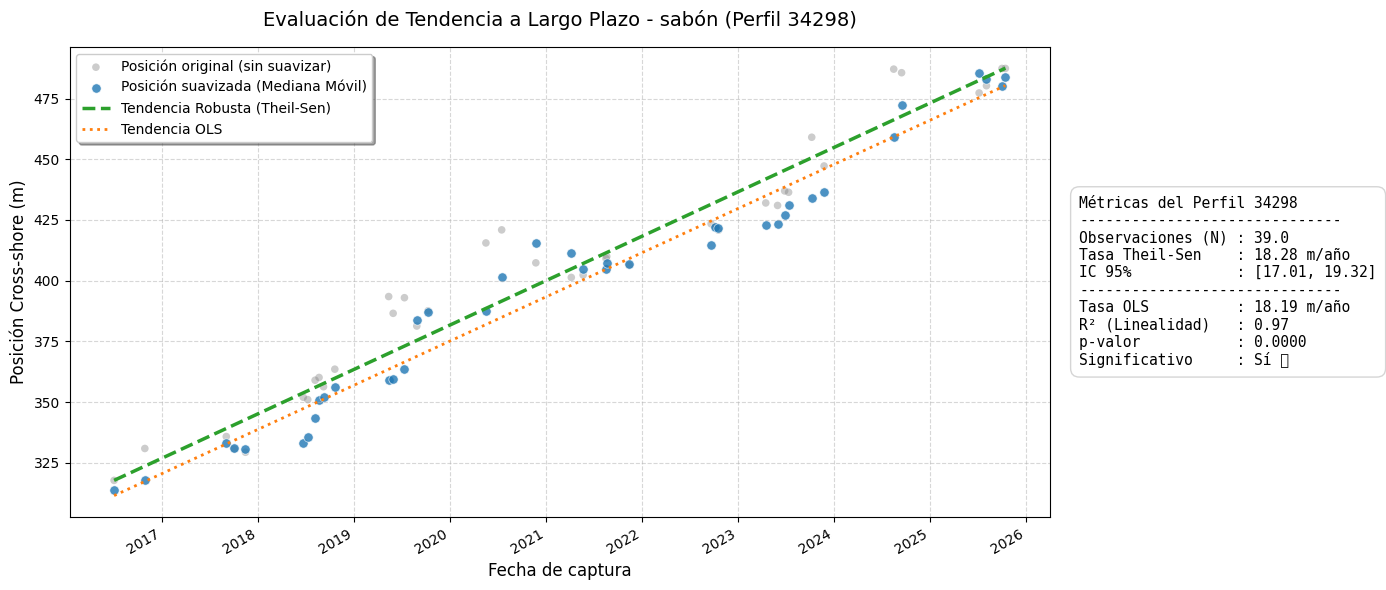

In [42]:
visualizar_tendencia_perfil(
    df_suavizado=smoothed_data, 
    df_tasas=tasas_resultados,
    profile_id=34298
)

In [ ]:
# Revisar huecos anuales por playa usando solo las líneas que superaron el filtro.
valid_profile_ids = tasas_resultados.loc[
    tasas_resultados["rate_theilsen_m_yr"].notna(), "ID_Perfil"
].drop_duplicates()
valid_beaches = (
    profiles[["ID_Perfil", "Playa", "provincia"]]
    .drop_duplicates("ID_Perfil")
    .merge(valid_profile_ids.to_frame(), on="ID_Perfil", how="inner")
    .drop_duplicates("Playa")
)

# filtered_data es la salida del SmartTidalFilter.
lineas_filtradas = (
    filtered_data[["ID_LineaCosta", "Playa", "datetime"]]
    .dropna(subset=["Playa", "datetime"])
    .drop_duplicates(["ID_LineaCosta", "Playa"])
    .assign(year=lambda df: df["datetime"].dt.year)
    .merge(valid_beaches[["Playa"]], on="Playa", how="inner", validate="many_to_one")
)

def revisar_huecos_por_playa(grupo):
    observed_years = sorted(grupo["year"].unique())
    expected_years = set(range(observed_years[0], observed_years[-1] + 1))
    missing_years = sorted(expected_years - set(observed_years))
    return pd.Series({
        "primer_año": observed_years[0],
        "último_año": observed_years[-1],
        "n_lineas_filtradas": grupo["ID_LineaCosta"].nunique(),
        "años_con_linea": ", ".join(map(str, observed_years)),
        "años_sin_linea": ", ".join(map(str, missing_years)) if missing_years else None,
        "n_años_sin_linea": len(missing_years),
    })

revision_huecos_playas = (
    lineas_filtradas.groupby("Playa")
    .apply(revisar_huecos_por_playa, include_groups=False)
    .reset_index()
    .merge(valid_beaches[["Playa", "provincia"]], on="Playa", how="left", validate="one_to_one")
)
revision_huecos_playas["hay_huecos_anuales"] = revision_huecos_playas["n_años_sin_linea"] > 0
revision_huecos_playas = revision_huecos_playas[
    ["Playa", "provincia", "primer_año", "último_año", "n_lineas_filtradas",
     "años_con_linea", "años_sin_linea", "n_años_sin_linea", "hay_huecos_anuales"]
].sort_values("Playa").reset_index(drop=True)

print(f"Playas con al menos un perfil con tasa: {len(revision_huecos_playas)}")
print(f"Playas con huecos anuales: {revision_huecos_playas['hay_huecos_anuales'].sum()}")
display(revision_huecos_playas)
revision_huecos_playas.to_csv(
    "revision_huecos_anuales_lineas_filtradas.csv",
    index=False,
    encoding="utf-8-sig",
)

In [ ]:
# Resultado final de la revisión anual por playa.
revision_huecos_playas.to_csv(
    "revision_huecos_anuales_lineas_filtradas.csv",
    index=False,
    encoding="utf-8-sig",
)
revision_huecos_playas